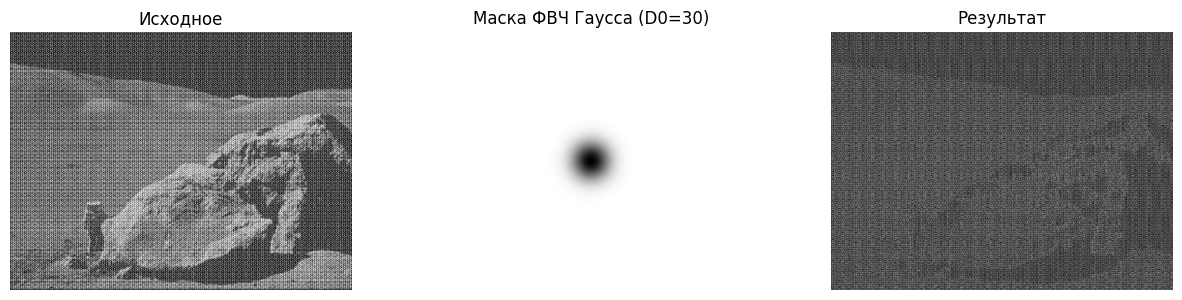

In [ ]:
import os
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

# 1. Загрузка с проверкой регистра
filename = 'periodic_noise.JPG' if os.path.exists('periodic_noise.JPG') else 'periodic_noise.jpg'
img = cv.imread(filename, cv.IMREAD_GRAYSCALE)
if img is None:
    raise ValueError(f"Не удалось прочитать изображение: {filename}")

rows, cols = img.shape
crow, ccol = rows // 2, cols // 2

# 2. Прямое DFT
dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

# 3. Фильтр Гаусса ФВЧ
D0 = 30  # радиус среза
u = np.arange(rows)
v = np.arange(cols)
V, U = np.meshgrid(v, u)
D = np.sqrt((U - crow)**2 + (V - ccol)**2)

ghpf = 1.0 - np.exp(-(D**2) / (2.0 * (D0**2)))
ghpf_mask = np.repeat(ghpf[:, :, np.newaxis], 2, axis=2)

# 4. Фильтрация и обратное DFT
fshift_filtered = dft_shift * ghpf_mask
f_ishift = np.fft.ifftshift(fshift_filtered)
img_back = cv.idft(f_ishift)
img_ghpf = cv.magnitude(img_back[:, :, 0], img_back[:, :, 1])
img_ghpf = cv.normalize(img_ghpf, None, 0, 255, cv.NORM_MINMAX, dtype=cv.CV_8U)

# 5. Вывод
plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img, cmap='gray'), plt.title('Исходное'), plt.axis('off')
plt.subplot(132), plt.imshow(ghpf, cmap='gray'), plt.title(f'Маска ФВЧ Гаусса (D0={D0})'), plt.axis('off')
plt.subplot(133), plt.imshow(img_ghpf, cmap='gray'), plt.title('Результат'), plt.axis('off')
plt.show()

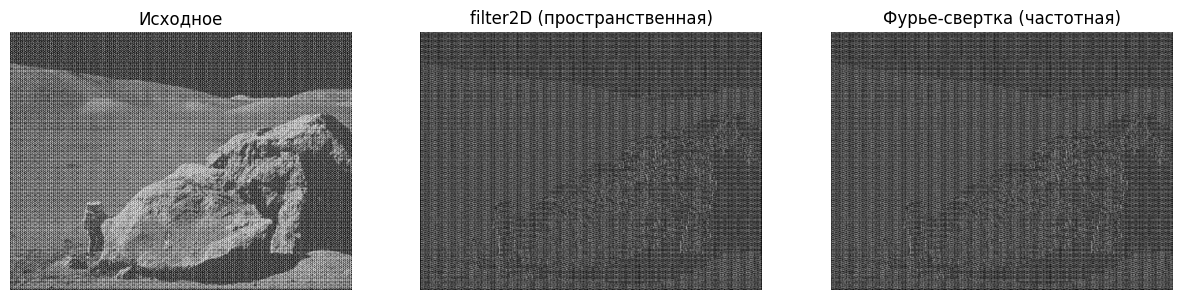

In [ ]:
# Пространственное ядро Собеля по X
kernel = np.array([[-1, 0, 1],
                   [-2, 0, 2],
                   [-1, 0, 1]], dtype=np.float32)

# Свертка во временной/пространственной области
conv_spatial = cv.filter2D(img, cv.CV_32F, kernel)

# Свертка в частотной области через DFT
padded_kernel = np.zeros_like(img, dtype=np.float32)
k_h, k_w = kernel.shape
padded_kernel[crow - k_h//2 : crow + k_h//2 + 1,
              ccol - k_w//2 : ccol + k_w//2 + 1] = kernel

dft_img = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_kernel = cv.dft(np.fft.ifftshift(padded_kernel), flags=cv.DFT_COMPLEX_OUTPUT)

# Поэлементное умножение комплексных чисел (a + ib)(c + id) = (ac - bd) + i(ad + bc)
dft_conv = np.zeros_like(dft_img)
dft_conv[:, :, 0] = dft_img[:, :, 0] * dft_kernel[:, :, 0] - dft_img[:, :, 1] * dft_kernel[:, :, 1]
dft_conv[:, :, 1] = dft_img[:, :, 0] * dft_kernel[:, :, 1] + dft_img[:, :, 1] * dft_kernel[:, :, 0]

conv_fourier = cv.idft(dft_conv, flags=cv.DFT_SCALE | cv.DFT_REAL_OUTPUT)

# Визуализация
plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img, cmap='gray'), plt.title('Исходное'), plt.axis('off')
plt.subplot(132), plt.imshow(np.abs(conv_spatial), cmap='gray'), plt.title('filter2D (пространственная)'), plt.axis('off')
plt.subplot(133), plt.imshow(np.abs(conv_fourier), cmap='gray'), plt.title('Фурье-свертка (частотная)'), plt.axis('off')
plt.show()

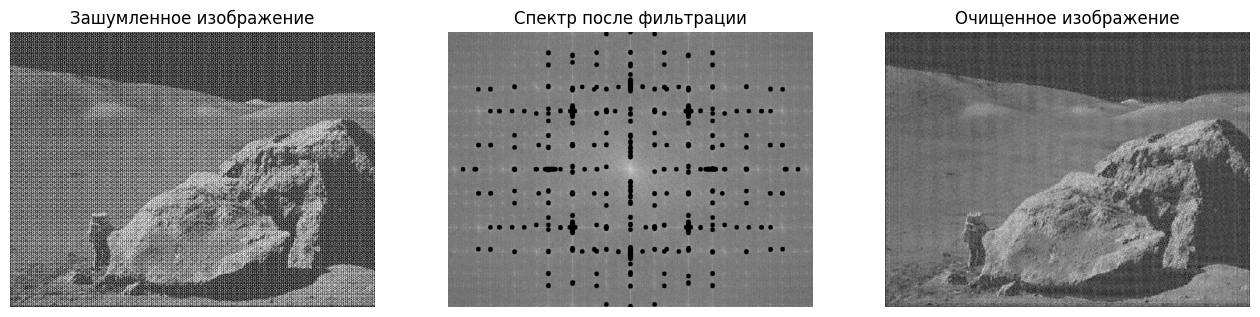

In [ ]:
# 1. Расчет спектра
dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
magnitude_spectrum = 20 * np.log(cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]) + 1)

# 2. Поиск пиков шума вне низкочастотного центра
temp_spectrum = magnitude_spectrum.copy()
cv.circle(temp_spectrum, (ccol, crow), 25, 0, -1)

threshold_val = np.percentile(temp_spectrum, 99.85)
noise_peaks = np.argwhere(temp_spectrum > threshold_val)

# 3. Построение маски режекторного фильтра
notch_mask = np.ones((rows, cols, 2), dtype=np.float32)
notch_radius = 5

for peak in noise_peaks:
    py, px = peak[0], peak[1]
    cv.circle(notch_mask, (px, py), notch_radius, (0, 0), -1)

# 4. Фильтрация и восстановление изображения
dft_shift_filtered = dft_shift * notch_mask
f_ishift_notch = np.fft.ifftshift(dft_shift_filtered)
img_restored = cv.idft(f_ishift_notch)
img_restored = cv.magnitude(img_restored[:, :, 0], img_restored[:, :, 1])
img_restored = cv.normalize(img_restored, None, 0, 255, cv.NORM_MINMAX, dtype=cv.CV_8U)

# 5. Визуализация
plt.figure(figsize=(16, 5))
plt.subplot(131), plt.imshow(img, cmap='gray'), plt.title('Зашумленное изображение'), plt.axis('off')
plt.subplot(132), plt.imshow(20 * np.log(cv.magnitude(dft_shift_filtered[:, :, 0], dft_shift_filtered[:, :, 1]) + 1), cmap='gray')
plt.title('Спектр после фильтрации'), plt.axis('off')
plt.subplot(133), plt.imshow(img_restored, cmap='gray'), plt.title('Очищенное изображение'), plt.axis('off')
plt.show()